# Plot Alignment-Validation Results

Reads the CSV accumulated by `validate_alignment.ipynb` (one row per fusion
checkpoint) and draws box plots comparing **matched** (blue) against **shuffled**
(red) audio-text pairs across the checkpoints, with the individual checkpoints
overlaid as dots.

Every figure is standalone (no subplots) and is saved to `figures/` as both PDF
(vector — use this in the paper) and PNG, so each plot can be dropped into the
paper individually. Needs `matplotlib` (`pip install matplotlib`) and no GPU.


In [13]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch


## Arguments


In [14]:
csv_path = "alignment_results.csv"   # written by validate_alignment.ipynb
fig_dir = "figures"                  # each plot is saved here as PDF + PNG
os.makedirs(fig_dir, exist_ok=True)


## Load

If a checkpoint was run more than once, only its most recent row is kept.


In [15]:
df = pd.read_csv(csv_path)
df = df.drop_duplicates(subset="ckpt", keep="last").reset_index(drop=True)

# class names, recovered from the per-class column names
class_names = [c[len("recall_"):-len("_matched")]
               for c in df.columns if c.startswith("recall_") and c.endswith("_matched")]

print(f"{len(df)} checkpoints, classes = {class_names}")
df


10 checkpoints, classes = ['N', 'H', 'A', 'S']


,timestamp,ckpt,split,n_examples,mmd_overall,pkd_matched,pkd_shuffled,cos_matched,cos_shuffled,wa_matched,...,mmd_S_matched,mmd_S_shuffled,cos_N_matched,cos_N_shuffled,cos_H_matched,cos_H_shuffled,cos_A_matched,cos_A_shuffled,cos_S_matched,cos_S_shuffled
0,2026-07-14 18:36:06,../F_Pllama_bal_gan_augmented_1.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.572409,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-07-14 18:45:09,../F_Pllama_bal_gan_augmented_2.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.584934,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-07-14 18:57:34,../F_Pllama_bal_gan_augmented_3.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.582243,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-07-15 10:26:16,../F_Pllama_bal_gan_augmented_4.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.615827,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-07-15 11:06:40,../F_Pllama_bal_gan_augmented_5.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.561369,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-07-15 11:31:04,../F_Pllama_bal_gan_augmented_6.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.537063,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2026-07-15 11:40:43,../F_Pllama_bal_gan_augmented_7.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.581501,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2026-07-15 11:49:30,../F_Pllama_bal_gan_augmented_8.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.607941,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2026-07-16 14:33:34,../F_Pllama_bal_gan_augmented_9.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.566101,...,1.724584,1.715476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2026-07-23 12:04:06,../F_Pllama_bal_gan_augmented_0.pt,test,10779,1.618744,7.981972,7.984876,0.159762,0.033609,0.531960,...,1.724584,1.715476,0.15493,0.032262,0.162916,0.034742,0.169956,0.03106,0.17041,0.042755


## Plot style and helpers

Blue = matched, red = shuffled (a colorblind-safe pair); pairing-independent
quantities are drawn in neutral gray. `grouped_box` draws the box plots with the
raw per-checkpoint points overlaid; `save_fig` writes the figure to `figures/`.


In [16]:
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b",
    "axes.titlecolor": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
    "pdf.fonttype": 42,   # embed editable (TrueType) text in the PDFs
})
COND_COLOR = {"matched": "#2a78d6", "shuffled": "#e34948"}
LEGEND = [Patch(facecolor=c, alpha=0.25, edgecolor=c, label=cond)
          for cond, c in COND_COLOR.items()]


def grouped_box(ax, groups, data, ylabel=""):
    """Grouped box plots with the raw per-checkpoint points overlaid.

    ``data`` maps a condition name to a list of value arrays, one per entry in
    ``groups``. Conditions are colored via COND_COLOR (neutral gray otherwise).
    """
    rng = np.random.default_rng(0)
    width, step = 0.3, 0.38
    conds = list(data)
    for k, cond in enumerate(conds):
        c = COND_COLOR.get(cond, "#898781")
        pos = np.arange(len(groups)) + (k - (len(conds) - 1) / 2) * step
        bp = ax.boxplot([np.asarray(v) for v in data[cond]], positions=pos,
                        widths=width, patch_artist=True, showfliers=False, zorder=2)
        for box in bp["boxes"]:
            box.set(facecolor=c, alpha=0.18, edgecolor=c, linewidth=1.1)
        for part in ("whiskers", "caps", "medians"):
            for line in bp[part]:
                line.set(color=c, linewidth=1.5 if part == "medians" else 1.1)
        for x0, vals in zip(pos, data[cond]):
            jit = rng.uniform(-width / 4, width / 4, len(vals))
            ax.scatter(x0 + jit, vals, s=14, color=c, alpha=0.9,
                       edgecolors="white", linewidths=0.4, zorder=3)
    ax.set_xticks(np.arange(len(groups)))
    ax.set_xticklabels(groups)
    ax.set_xlim(-0.6, len(groups) - 0.4)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel(ylabel)


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(fig_dir, f"{name}.{ext}"),
                    dpi=300, bbox_inches="tight")
    print(f"saved {fig_dir}/{name}.pdf and .png")


def cond_data(keys):
    """{condition: [df[f"{key}_{condition}"] for key in keys]}"""
    return {cond: [df[f"{k}_{cond}"] for k in keys]
            for cond in ("matched", "shuffled")}


## Figures

One figure per cell; edit sizes/labels per figure as needed for the paper.


saved figures/fusion_recognition.pdf and .png


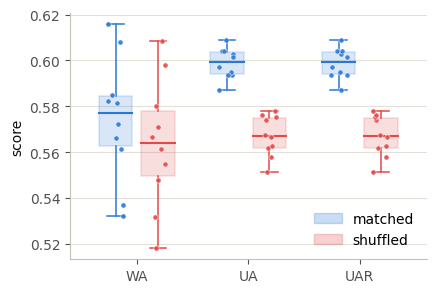

In [17]:
# fusion recognition -- WA / UA / UAR, matched vs shuffled
fig, ax = plt.subplots(figsize=(4.6, 3.2))
grouped_box(ax, ["WA", "UA", "UAR"], cond_data(["wa", "ua", "uar"]), ylabel="score")
ax.legend(handles=LEGEND, frameon=False)
save_fig(fig, "fusion_recognition")
plt.show()


saved figures/paired_cosine.pdf and .png


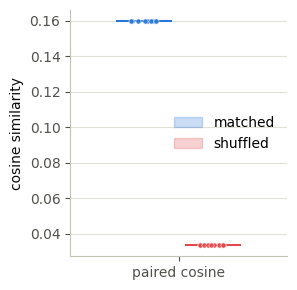

In [18]:
# paired cosine similarity, matched vs shuffled
fig, ax = plt.subplots(figsize=(2.8, 3.2))
grouped_box(ax, ["paired cosine"], cond_data(["cos"]), ylabel="cosine similarity")
ax.legend(handles=LEGEND, frameon=False)
save_fig(fig, "paired_cosine")
plt.show()


saved figures/paired_kernel_distance.pdf and .png


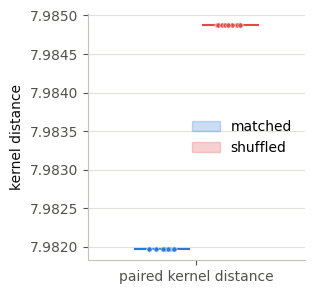

In [19]:
# paired kernel distance, matched vs shuffled
fig, ax = plt.subplots(figsize=(2.8, 3.2))
grouped_box(ax, ["paired kernel distance"], cond_data(["pkd"]), ylabel="kernel distance")
ax.legend(handles=LEGEND, frameon=False)
save_fig(fig, "paired_kernel_distance")
plt.show()


saved figures/mmd_overall.pdf and .png


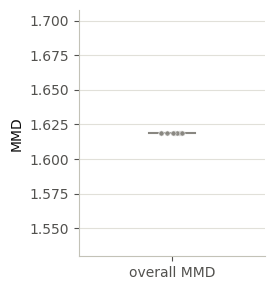

In [20]:
# overall MMD (pairing-independent -- identical for matched/shuffled)
fig, ax = plt.subplots(figsize=(2.4, 3.2))
grouped_box(ax, ["overall MMD"], {"overall": [df["mmd_overall"]]}, ylabel="MMD")
save_fig(fig, "mmd_overall")
plt.show()


saved figures/per_class_recall.pdf and .png


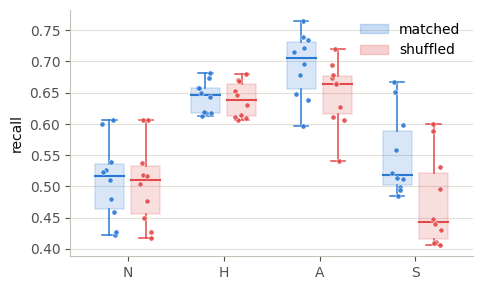

In [21]:
# per-class recall of the fused head, matched vs shuffled
fig, ax = plt.subplots(figsize=(5.2, 3.2))
grouped_box(ax, class_names,
            {cond: [df[f"recall_{c}_{cond}"] for c in class_names]
             for cond in ("matched", "shuffled")},
            ylabel="recall")
ax.legend(handles=LEGEND, frameon=False)
save_fig(fig, "per_class_recall")
plt.show()


saved figures/per_class_mmd.pdf and .png


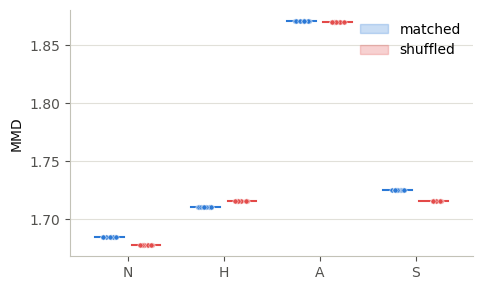

In [22]:
# per-class MMD between audio features and their paired text features
fig, ax = plt.subplots(figsize=(5.2, 3.2))
grouped_box(ax, class_names,
            {cond: [df[f"mmd_{c}_{cond}"] for c in class_names]
             for cond in ("matched", "shuffled")},
            ylabel="MMD")
ax.legend(handles=LEGEND, frameon=False)
save_fig(fig, "per_class_mmd")
plt.show()


## Summary table (mean ± std across checkpoints)

Handy for the paper's results table.


In [23]:
pairs = [("WA", "wa"), ("UA", "ua"), ("UAR", "uar"),
         ("paired cosine", "cos"), ("paired kernel distance", "pkd")]
summary = pd.DataFrame(
    [{"metric": name,
      "matched": f"{df[k + '_matched'].mean():.4f} ± {df[k + '_matched'].std():.4f}",
      "shuffled": f"{df[k + '_shuffled'].mean():.4f} ± {df[k + '_shuffled'].std():.4f}"}
     for name, k in pairs]
    + [{"metric": "overall MMD",
        "matched": f"{df['mmd_overall'].mean():.4f} ± {df['mmd_overall'].std():.4f}",
        "shuffled": "(identical)"},
       {"metric": "flip rate",
        "matched": f"{df['flip_rate'].mean():.4f} ± {df['flip_rate'].std():.4f}",
        "shuffled": ""}])
summary


,metric,matched,shuffled
0,WA,0.5741 ± 0.0269,0.5638 ± 0.0278
1,UA,0.5988 ± 0.0066,0.5671 ± 0.0088
2,UAR,0.5988 ± 0.0066,0.5671 ± 0.0088
3,paired cosine,0.1598 ± 0.0000,0.0336 ± 0.0000
4,paired kernel distance,7.9820 ± 0.0000,7.9849 ± 0.0000
5,overall MMD,1.6187 ± 0.0000,(identical)
6,flip rate,0.1965 ± 0.0123,


## Cosine-similarity table — whole split and per class

Paired cosine similarity, matched vs shuffled, mean ± std **across
checkpoints**: whole split plus each emotion class. The per-class columns only
exist in rows written after they were added to `validate_alignment.ipynb` —
older rows are skipped for those entries (`n_ckpts` = rows contributing).

In [24]:
def _cos_stats(col):
    s = df[col].dropna() if col in df else pd.Series(dtype=float)
    return (f"{s.mean():.4f} ± {s.std():.4f}" if len(s) else "—"), len(s)

rows = []
for name, key in [("overall", "cos")] + [(c, f"cos_{c}") for c in class_names]:
    m_txt, n = _cos_stats(f"{key}_matched")
    s_txt, _ = _cos_stats(f"{key}_shuffled")
    if f"{key}_matched" in df:
        g = (df[f"{key}_matched"] - df[f"{key}_shuffled"]).dropna()
        g_txt = f"{g.mean():.4f} ± {g.std():.4f}"
    else:
        g_txt = "—"
    rows.append({"class": name, "matched": m_txt, "shuffled": s_txt,
                 "gap": g_txt, "n_ckpts": n})
cos_table = pd.DataFrame(rows).set_index("class")
cos_table

,matched,shuffled,gap,n_ckpts
class,,,,
overall,0.1598 ± 0.0000,0.0336 ± 0.0000,0.1262 ± 0.0000,10
N,0.1549 ± nan,0.0323 ± nan,0.1227 ± nan,1
H,0.1629 ± nan,0.0347 ± nan,0.1282 ± nan,1
A,0.1700 ± nan,0.0311 ± nan,0.1389 ± nan,1
S,0.1704 ± nan,0.0428 ± nan,0.1277 ± nan,1
